# Análise de Dados do Brasileirão

## Objetivo

Investigar padrões históricos do Campeonato Brasileiro de Futebol,
analisando a quantidade de gols, a distribuição dos resultados
e a vantagem de jogar em casa.

## Base de dados

A análise utiliza o arquivo `campeonato-brasileiro-full.csv`,
que contém informações sobre partidas, equipes, placares,
datas e estádios.


## 1. Carregamento e Preparação dos Dados

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
caminho = "../data/raw/campeonato-brasileiro-full.csv"
df = pd.read_csv(caminho)
df.head()

,ID,rodata,data,hora,mandante,visitante,formacao_mandante,formacao_visitante,tecnico_mandante,tecnico_visitante,vencedor,arena,mandante_Placar,visitante_Placar,mandante_Estado,visitante_Estado,arrecadacao
0,1,1,29/03/2003,16:00,Guarani,Vasco,NaN,NaN,NaN,NaN,Guarani,Brinco de Ouro,4,2,SP,RJ,NaN
1,2,1,29/03/2003,16:00,Athletico-PR,Gremio,NaN,NaN,NaN,NaN,Athletico-PR,Arena da Baixada,2,0,PR,RS,NaN
2,3,1,30/03/2003,16:00,Flamengo,Coritiba,NaN,NaN,NaN,NaN,-,Maracanã,1,1,RJ,PR,NaN
3,4,1,30/03/2003,16:00,Goias,Paysandu,NaN,NaN,NaN,NaN,-,Serra Dourada,2,2,GO,PA,NaN
4,5,1,30/03/2003,16:00,Internacional,Ponte Preta,NaN,NaN,NaN,NaN,-,Beira Rio,1,1,RS,SP,NaN


In [3]:
df.shape

(9165, 17)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9165 entries, 0 to 9164
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  9165 non-null   int64  
 1   rodata              9165 non-null   int64  
 2   data                9165 non-null   str    
 3   hora                9165 non-null   str    
 4   mandante            9165 non-null   str    
 5   visitante           9165 non-null   str    
 6   formacao_mandante   4190 non-null   str    
 7   formacao_visitante  4190 non-null   str    
 8   tecnico_mandante    4555 non-null   str    
 9   tecnico_visitante   4555 non-null   str    
 10  vencedor            9165 non-null   str    
 11  arena               9165 non-null   str    
 12  mandante_Placar     9165 non-null   int64  
 13  visitante_Placar    9165 non-null   int64  
 14  mandante_Estado     9165 non-null   str    
 15  visitante_Estado    9165 non-null   str    
 16  arrecadacao      

In [5]:
df.isnull().sum()

ID                       0
rodata                   0
data                     0
hora                     0
mandante                 0
visitante                0
formacao_mandante     4975
formacao_visitante    4975
tecnico_mandante      4610
tecnico_visitante     4610
vencedor                 0
arena                    0
mandante_Placar          0
visitante_Placar         0
mandante_Estado          0
visitante_Estado         0
arrecadacao           8785
dtype: int64

In [6]:
df["data"] = pd.to_datetime(
    df["data"],
    format = "%d/%m/%Y",
    errors = "coerce"
)

df["gols_total"] = (df["mandante_Placar"] + df["visitante_Placar"])
df["saldo_mandante"] = (df["mandante_Placar"] - df["visitante_Placar"])
df["ano"] = df["data"].dt.year

In [7]:
df[
    [
        "data",
        "mandante",
        "visitante",
        "mandante_Placar",
        "visitante_Placar",
        "gols_total",
        "saldo_mandante",
        "ano"
    ]
].head()

,data,mandante,visitante,mandante_Placar,visitante_Placar,gols_total,saldo_mandante,ano
0,2003-03-29,Guarani,Vasco,4,2,6,2,2003
1,2003-03-29,Athletico-PR,Gremio,2,0,2,2,2003
2,2003-03-30,Flamengo,Coritiba,1,1,2,0,2003
3,2003-03-30,Goias,Paysandu,2,2,4,0,2003
4,2003-03-30,Internacional,Ponte Preta,1,1,2,0,2003


### 1.1. Como a Média de Gols por Partida variou ao longo das Temporadas do Brasileirão?

In [8]:
media_gols = df["gols_total"].mean()
print(f"Média de gols por partida: {media_gols:.2f}")

Média de gols por partida: 2.56


In [9]:
media_por_ano = df.groupby("ano")["gols_total"].mean()
media_por_ano

ano
2003    2.884058
2004    2.778986
2005    3.140693
2006    2.710526
2007    2.755263
2008    2.723684
2009    2.878947
2010    2.573684
2011    2.676316
2012    2.473684
2013    2.463158
2014    2.263158
2015    2.360526
2016    2.406332
2017    2.428947
2018    2.176316
2019    2.305263
2020    2.440299
2021    2.300813
2022    2.381579
2023    2.489474
2024    2.444737
2025    2.523684
Name: gols_total, dtype: float64

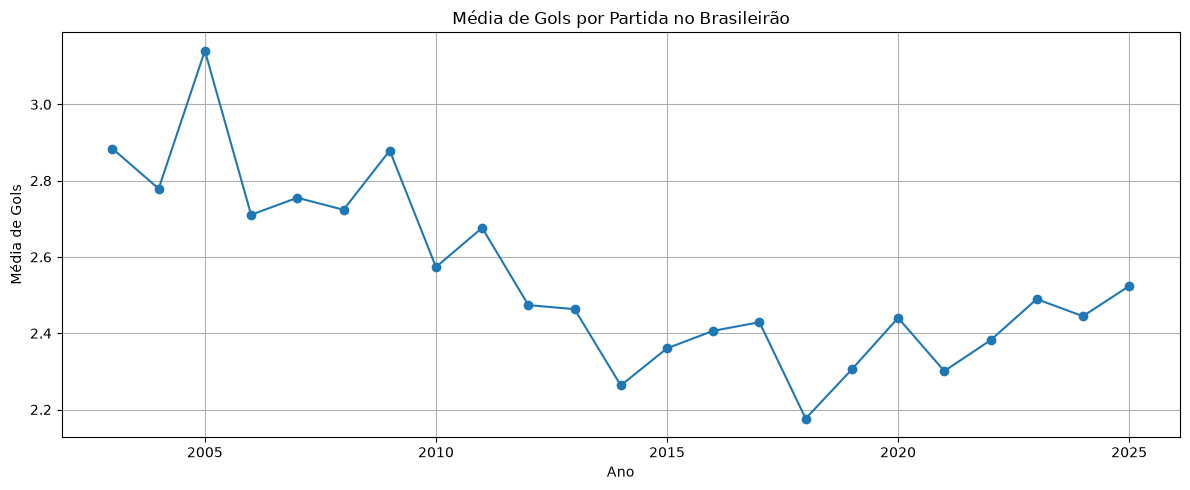

In [10]:
media_por_ano.plot(kind = "line", figsize = (12, 5), marker = "o")

plt.title("Média de Gols por Partida no Brasileirão")
plt.xlabel("Ano")
plt.ylabel("Média de Gols")
plt.grid(True)
plt.tight_layout()
plt.show()

**Interpretação:**

A média de gols apresentou variações significativas ao longo das temporadas. No início do período, os jogos tinham médias relativamente elevadas, com destaque para 2005, quando foram registrados aproximadamente 3,14 gols por partida. No entanto, posteriormente observa-se uma tendência geral de redução, atingindo o menor valor em 2018, com cerca de 2,18 gols.  

A partir de 2019, a média voltou a oscilar, apresentando recuperação em alguns anos. Em 2025, chegou a aproximadamente 2,52 gols por partida, valor próximo da média geral de 2,56.

### 1.2. Como Ocorreu a Distribuição Geral dos Resultados das Partidas?

In [11]:
def classificar_resultado(linha):
    if linha["mandante_Placar"] > linha["visitante_Placar"]:
        return "Vitória do Mandante"

    elif linha["mandante_Placar"] < linha["visitante_Placar"]:
        return "Vitória do Visitante"

    else:
        return "Empate"

df["resultado"] = df.apply(classificar_resultado, axis = 1)

contagem_resultados = df["resultado"].value_counts()
contagem_resultados

resultado
Vitória do Mandante     4550
Empate                  2421
Vitória do Visitante    2194
Name: count, dtype: int64

In [12]:
resultados_por_ano = pd.crosstab(df["ano"], df["resultado"], normalize = "index") * 100
resultados_por_ano.round(2)

resultado,Empate,Vitória do Mandante,Vitória do Visitante
ano,,,
2003,25.72,53.80,20.47
2004,25.36,52.17,22.46
2005,22.29,50.87,26.84
2006,25.53,50.26,24.21
2007,23.68,50.53,25.79
2008,25.26,54.74,20.00
2009,26.84,51.32,21.84
2010,31.05,47.11,21.84
2011,27.63,48.42,23.95


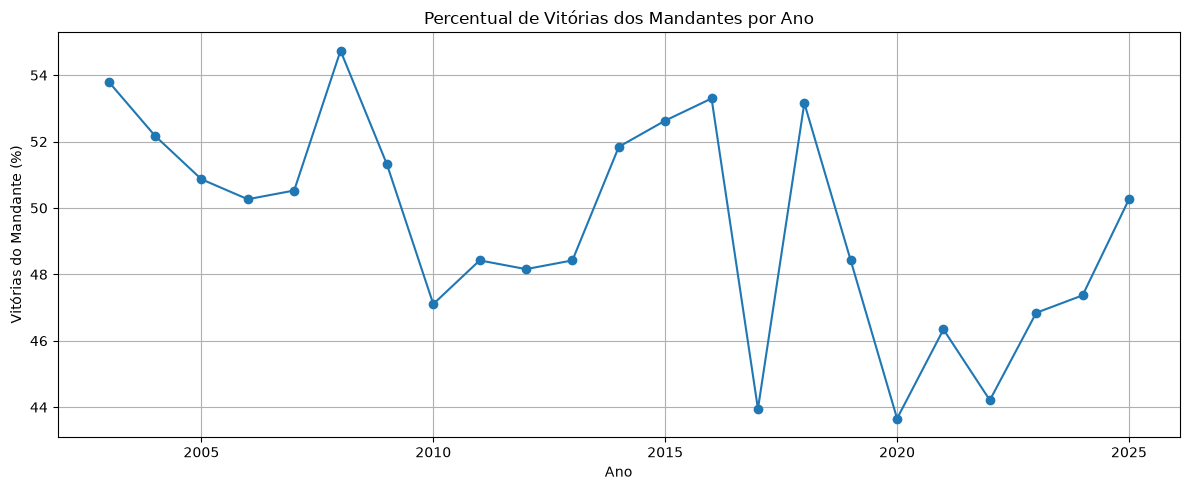

In [13]:
resultados_por_ano["Vitória do Mandante"].plot(kind = "line", figsize = (12, 5), marker = "o")

plt.title("Percentual de Vitórias dos Mandantes por Ano")
plt.xlabel("Ano")
plt.ylabel("Vitórias do Mandante (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

**Interpretação:**

As vitórias dos mandantes foram o resultado mais frequente, representando aproximadamente metade das partidas analisadas. Os empates corresponderam a cerca de 1/4 dos jogos, enquanto as vitórias dos visitantes foram menos frequentes.

Isso sugere uma possível existência de vantagem associada a jogar em casa, visto que historicamente, os times mandantes venceram mais vezes do que os visitantes.

### 1.3. Como se Comportou o Percentual de Vitórias do Mandante por Temporada?

In [14]:
vitorias_mandante = resultados_por_ano["Vitória do Mandante"]

print("Maior percentual:")
print(vitorias_mandante.idxmax(), vitorias_mandante.max())

print("\nMenor Percentual:")
print(vitorias_mandante.idxmin(), vitorias_mandante.min())

Maior percentual:
2008 54.736842105263165

Menor Percentual:
2020 43.656716417910445


In [15]:
resultados_por_ano[
    [
        "Vitória do Mandante",
    ]
].round(2)

resultado,Vitória do Mandante
ano,
2003,53.80
2004,52.17
2005,50.87
2006,50.26
2007,50.53
2008,54.74
2009,51.32
2010,47.11
2011,48.42


**Interpretação:**

O percentual de vitórias dos mandantes apresentou consideráveis oscilações ao longo do período. Em 2008, aproximadamente 55% das partidas terminaram com vitória do time da casa, enquanto em 2020 esse percentual caiu para cerca de 44% - o menor valor registrado na série.

A queda observada em 2020 chama a atenção por coincidir com o período da pandemia de COVID-19, quando diversas partidas ocorreram sem público nos estádios.

Esse resultado levanta a possível hipótese de que a ausência de torcedores possa ter contribuído para a redução da vantagem de jogar em casa. Entretanto, vale salientar que a coincidência temporal não comprova uma relação de causa e efeito.

### 1.4. Como os Resultados Antes, Durante e Depois da Pandemia se Distribuíram?

In [16]:
def classificar_periodo(ano):
    if ano <= 2019:
        return "Pré-pandemia"

    elif ano <= 2021:
        return "Período de Pandemia"

    else:
        return "Pós-pandemia"

df["periodo"] = df["ano"].apply(classificar_periodo)

In [17]:
df_recorte = df[df["ano"].between(2017, 2023)].copy()

comparacao_recorte = pd.crosstab(df_recorte["periodo"], df_recorte["resultado"], normalize = "index") * 100
comparacao_recorte.round(2)

resultado,Empate,Vitória do Mandante,Vitória do Visitante
periodo,,,
Período de Pandemia,29.08,45.39,25.53
Pré-pandemia,27.28,48.51,24.21
Pós-pandemia,27.11,45.53,27.37


**Interpretação:**

* **Pré-pandemia:** as vitórias dos mandantes representaram 48,51% das partidas, enquanto os empates corresponderam a 27,28% e as vitórias dos visitantes a 24,21%.

* **Durante a pandemia:** o percentual de vitórias dos mandantes caiu para 45,39%, enquanto os empates aumentaram para 29,08%, o maior percentual entre os três períodos. As vitórias dos visitantes também aumentaram, chegando a 25,53%.

* **Pós-pandemia:** as vitórias dos mandantes permaneceram em um patamar próximo ao observado durante a pandemia, com 45,53%. Já as vitórias dos visitantes aumentaram para 27,37%, o maior percentual entre os três períodos.

Os resultados indicam uma redução da participação das vitórias dos mandantes em comparação com o período pré-pandemia. Ademais, no recorte pós-pandemia, as vitórias dos visitantes passaram a representar uma parcela maior dos resultados em relação aos períodos anteriores.

Porém, como a comparação utiliza apenas duas a três temporadas por período, não é possível atribuir essas mudanças exclusivamente à pandemia.

## 2. Desempenho Ofensivo e Defensivo das Equipes

### Objetivo

Identificar as equipes com maior produção ofensiva, melhor desempenho defensivo e maior saldo de gols no período analisado.

Para isso, serão utilizados os placares das partidas, considerando os gols marcados e sofridos por cada equipe. Além dos totais históricos, serão calculadas médias por partida para reduzir o efeito das diferenças na quantidade de jogos disputados.

In [20]:
mandantes = {
    "equipe": df["mandante"],
    "gols_marcados": df["mandante_Placar"],
    "gols_sofridos": df["visitante_Placar"]
}

df_mandantes = pd.DataFrame(mandantes)
df_mandantes

,equipe,gols_marcados,gols_sofridos
0,Guarani,4,2
1,Athletico-PR,2,0
2,Flamengo,1,1
3,Goias,2,2
4,Internacional,1,1
...,...,...,...
9160,Santos,3,0
9161,Sport,0,4
9162,Botafogo-RJ,4,2
9163,Atletico-MG,5,0


In [21]:
visitantes = {
    "equipe": df["visitante"],
    "gols_marcados": df["visitante_Placar"],
    "gols_sofridos": df["mandante_Placar"]
}

df_visitantes = pd.DataFrame(visitantes)
df_visitantes

,equipe,gols_marcados,gols_sofridos
0,Vasco,2,4
1,Gremio,0,2
2,Coritiba,1,1
3,Paysandu,2,2
4,Ponte Preta,1,1
...,...,...,...
9160,Cruzeiro,0,3
9161,Gremio,4,0
9162,Fortaleza,2,4
9163,Vasco,0,5


In [24]:
df_equipes = pd.concat([df_mandantes, df_visitantes], ignore_index = True)
df_equipes.head()

,equipe,gols_marcados,gols_sofridos
0,Guarani,4,2
1,Athletico-PR,2,0
2,Flamengo,1,1
3,Goias,2,2
4,Internacional,1,1


In [25]:
df_equipes.shape

(18330, 3)

In [29]:
gols_marcados_equipes = df_equipes.groupby("equipe")["gols_marcados"].sum()
gols_marcados_equipes

equipe
America-MG          227
America-RN           24
Athletico-PR       1072
Atletico-GO         317
Atletico-MG        1221
Avai                274
Bahia               579
Barueri              59
Botafogo-RJ         993
Bragantino          292
Brasiliense          49
CSA                  24
Ceara               311
Chapecoense         261
Corinthians        1095
Coritiba            693
Criciuma            236
Cruzeiro           1111
Cuiaba              134
Figueirense         530
Flamengo           1308
Fluminense         1181
Fortaleza           470
Goias               789
Gremio             1110
Gremio Prudente      39
Guarani             140
Internacional      1138
Ipatinga             37
Joinville            26
Juventude           416
Mirassol             63
Nautico             224
Palmeiras          1203
Parana              312
Paysandu            193
Ponte Preta         414
Portuguesa          137
Santa Cruz           86
Santo Andre          46
Santos             1223
Sao Caeta

In [30]:
gols_sofridos_equipes = df_equipes.groupby("equipe")["gols_sofridos"].sum()
gols_sofridos_equipes

equipe
America-MG          332
America-RN           80
Athletico-PR       1011
Atletico-GO         421
Atletico-MG        1076
Avai                415
Bahia               660
Barueri              52
Botafogo-RJ         948
Bragantino          285
Brasiliense          68
CSA                  58
Ceara               357
Chapecoense         359
Corinthians         924
Coritiba            787
Criciuma            325
Cruzeiro            922
Cuiaba              167
Figueirense         622
Flamengo           1031
Fluminense         1110
Fortaleza           518
Goias               839
Gremio              934
Gremio Prudente      64
Guarani             180
Internacional       945
Ipatinga             67
Joinville            48
Juventude           568
Mirassol             39
Nautico             318
Palmeiras           906
Parana              369
Paysandu            245
Ponte Preta         534
Portuguesa          157
Santa Cruz          145
Santo Andre          61
Santos             1032
Sao Caeta

### 2.1. Quais Equipes Marcaram mais Gols?

In [41]:
gols_marcados_equipes.sort_values(ascending=False).head(15)

equipe
Flamengo         1308
Sao Paulo        1259
Santos           1223
Atletico-MG      1221
Palmeiras        1203
Fluminense       1181
Internacional    1138
Cruzeiro         1111
Gremio           1110
Corinthians      1095
Athletico-PR     1072
Botafogo-RJ       993
Vasco             886
Goias             789
Coritiba          693
Name: gols_marcados, dtype: int64

### 2.2. Quais Equipes Sofreram Menos Gols?

In [42]:
gols_sofridos_equipes.sort_values(ascending=True).head(15)

equipe
Mirassol            39
Joinville           48
Barueri             52
CSA                 58
Santo Andre         61
Gremio Prudente     64
Ipatinga            67
Brasiliense         68
America-RN          80
Santa Cruz         145
Portuguesa         157
Cuiaba             167
Guarani            180
Sao Caetano        199
Paysandu           245
Name: gols_sofridos, dtype: int64

### 2.3. Quais Equipes Tiveram o Maior Saldo de Gols?

In [45]:
saldo_gols_equipes = gols_marcados_equipes - gols_sofridos_equipes
saldo_gols_equipes.sort_values(ascending=False).head(15)

equipe
Palmeiras        297
Sao Paulo        290
Flamengo         277
Internacional    193
Santos           191
Cruzeiro         189
Gremio           176
Corinthians      171
Atletico-MG      145
Fluminense        71
Athletico-PR      61
Botafogo-RJ       45
Mirassol          24
Sao Caetano       10
Barueri            7
dtype: int64

In [63]:
totais_equipes = df_equipes.groupby("equipe").agg(gols_marcados = ("gols_marcados", "sum"), gols_sofridos = ("gols_sofridos", "sum"))
totais_equipes["saldo_gols"] = totais_equipes["gols_marcados"] - totais_equipes["gols_sofridos"]
totais_equipes.head(10)

,gols_marcados,gols_sofridos,saldo_gols
equipe,,,
America-MG,227,332,-105
America-RN,24,80,-56
Athletico-PR,1072,1011,61
Atletico-GO,317,421,-104
Atletico-MG,1221,1076,145
Avai,274,415,-141
Bahia,579,660,-81
Barueri,59,52,7
Botafogo-RJ,993,948,45


In [68]:
partidas_equipes = df_equipes.groupby("equipe").size()
partidas_equipes

equipe
America-MG         228
America-RN          38
Athletico-PR       818
Atletico-GO        304
Atletico-MG        855
Avai               266
Bahia              502
Barueri             38
Botafogo-RJ        772
Bragantino         228
Brasiliense         42
CSA                 38
Ceara              304
Chapecoense        265
Corinthians        856
Coritiba           590
Criciuma           206
Cruzeiro           780
Cuiaba             152
Figueirense        438
Flamengo           894
Fluminense         894
Fortaleza          392
Goias              590
Gremio             814
Gremio Prudente     38
Guarani            130
Internacional      856
Ipatinga            38
Joinville           38
Juventude          362
Mirassol            38
Nautico            190
Palmeiras          810
Parana             248
Paysandu           134
Ponte Preta        362
Portuguesa         114
Santa Cruz          76
Santo Andre         38
Santos             856
Sao Caetano        172
Sao Paulo          894
Spor

In [70]:
totais_equipes["media_gols_marcados"] = totais_equipes["gols_marcados"]/partidas_equipes
totais_equipes.head(15)

,gols_marcados,gols_sofridos,saldo_gols,media_gols_marcados
equipe,,,,
America-MG,227,332,-105,0.995614
America-RN,24,80,-56,0.631579
Athletico-PR,1072,1011,61,1.310513
Atletico-GO,317,421,-104,1.042763
Atletico-MG,1221,1076,145,1.428070
Avai,274,415,-141,1.030075
Bahia,579,660,-81,1.153386
Barueri,59,52,7,1.552632
Botafogo-RJ,993,948,45,1.286269
